<div align="center">

**Міністерство освіти і науки України**  
**Національний університет «Львівська політехніка»**  
**Інститут комп’ютерних наук та інформаційних технологій**  
**Кафедра автоматизованих систем управління**  

<br><br>

### **Звіт**
**до виконаної лабораторної роботи №2**  
**з дисципліни:** «Основи смарт-технологій і систем»  
**на тему::** «Тренування, оцінювання та оптимізація моделі машинного навчання»  

</div>

<br>

<div style="width: 100%; overflow: hidden;">
  <div style="float: right; text-align: left; width: 40%; margin-right: 10%;">
    <strong>Виконав:</strong> студент групи ОІ-21сп<br>
    <strong>Кукуляк Дмитро</strong><br><br>
    <strong>Прийняв:</strong> асистент кафедри АСУ<br>
    <strong>Ткачук К. І.</strong>
  </div>
</div>

<br><br>

<div align="center">

**Львів — 2026**  

</div>
<hr style="border: 1px solid #ccc;">

# Лабораторна робота №3
**Тема:** Тренування, оцінювання та оптимізація моделі машинного навчання  
**Мета:** Підібрати відповідну модель для бізнес-проблеми, налаштувати її тренування, обрати метрики, оптимізувати гіперпараметри та оцінити
важливість ознак, використовуючи реальні дані з бази підприємства.

## 0. Ініціалізація середовища та перевірка БД

In [132]:
from pathlib import Path
from datetime import datetime, timezone
import sqlite3, shutil, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from IPython.display import display

SEED = 42
ROOT = Path.cwd()
SOURCE_DB = ROOT / 'student_burnout.db'
if not SOURCE_DB.is_file():
    raise FileNotFoundError(f'У папці {ROOT} немає student_burnout.db. Поклади базу поруч із lab3.ipynb.')
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
DB = ROOT / 'student_burnout_lab3.db'
shutil.copy2(SOURCE_DB, DB)
MODEL_DIR = ROOT / 'models'; MODEL_DIR.mkdir(exist_ok=True)
conn = sqlite3.connect(DB)
display(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", conn))
print('Оригінал:', SOURCE_DB, '\nРобоча БД:', DB)

,name
0,students_burnout
1,students_burnout_features


Оригінал: c:\Users\Taras Yosyfiv\Desktop\політехніка\2 kurs 1 term\смарт системи\кукуляк_звіти\лаб2\student_burnout.db 
Робоча БД: c:\Users\Taras Yosyfiv\Desktop\політехніка\2 kurs 1 term\смарт системи\кукуляк_звіти\лаб2\student_burnout_lab3.db


## 1. Вибір техніки моделювання
Задача навчального аналітичного підрозділу університету — **завчасно визначати рівень ризику академічного вигорання**, щоб фахівці могли приділити увагу студентам, які потребують додаткової підтримки. Ціль `burnout_risk_level` набуває **трьох дискретних значень**: `Low`, `Medium`, `High`. Отже, це **багатокласова класифікація**, а не регресія (яка прогнозує неперервне число).

Порівнюємо **Logistic Regression** (інтерпретована лінійна базова модель), **Decision Tree** (зрозумілі нелінійні правила) та **Random Forest** (ансамбль дерев, що враховує складніші взаємодії). Модель отримує 12 характеристик, доступних до завершення семестру; `post_semester_gpa`, `skill_retention_score`, ціль, ID і часову позначку не використовуємо як предиктори, щоб уникнути витоку цільової інформації.

Класифікатор визначає одну з трьох категорій ризику для кожного студента. Прогноз використовується лише як допоміжна інформація, а не як діагноз.

In [133]:
df = pd.read_sql_query('SELECT * FROM students_burnout', conn)
TARGET = 'burnout_risk_level'; LABELS = ['Low','Medium','High']
FEATURES = ['major_category','year_of_study','pre_semester_gpa','weekly_genai_hours',
            'primary_use_case','prompt_engineering_skill','tool_diversity',
            'paid_subscription','traditional_study_hours','perceived_ai_dependency',
            'institutional_policy','anxiety_level_during_exams']
assert set(FEATURES+[TARGET,'student_id']).issubset(df.columns)
X = df[FEATURES].copy(); y = df[TARGET].copy(); ids = df['student_id']
print('Дані:', df.shape, '| Ознак:', X.shape[1]); display(df[FEATURES+[TARGET]].head())

Дані: (50000, 17) | Ознак: 12


,major_category,year_of_study,pre_semester_gpa,weekly_genai_hours,primary_use_case,prompt_engineering_skill,tool_diversity,paid_subscription,traditional_study_hours,perceived_ai_dependency,institutional_policy,anxiety_level_during_exams,burnout_risk_level
0,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,1,8.13,5,Allowed_With_Citation,6,High
1,Medical,Junior,3.821,1.12,Ideation,Advanced,5,0,16.65,3,Allowed_With_Citation,9,Low
2,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,0,10.35,5,Strict_Ban,9,Medium
3,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,0,15.23,2,Allowed_With_Citation,2,Medium
4,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,0,12.55,4,Allowed_With_Citation,4,Medium


## 2. Модельні припущення
**Logistic Regression** допускає адитивний лінійний зв'язок ознак із логітами й чутлива до сильної мультиколінеарності. **Decision Tree** не потребує лінійності, але може перенавчатися. **Random Forest** агрегує дерева для зниження дисперсії. Незалежність записів припускаємо, оскільки один `student_id` відповідає одному студенту. Перевіряємо пропуски, дублікати та пропорції класів.

Пропусків: 0
Дублікатів Student_ID: 0


,кількість,відсоток
burnout_risk_level,,
Low,16369,32.74
Medium,21144,42.29
High,12487,24.97


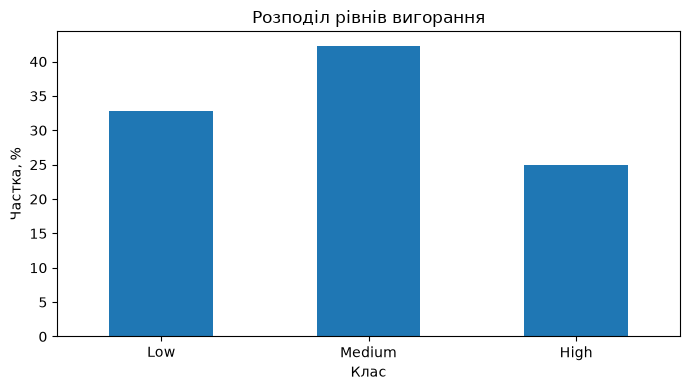

In [134]:
print('Пропусків:', int(df[FEATURES+[TARGET]].isna().sum().sum()))
print('Дублікатів Student_ID:', int(df.student_id.duplicated().sum()))
shares = y.value_counts().reindex(LABELS)
display(pd.DataFrame({'кількість':shares,'відсоток':(shares/len(y)*100).round(2)}))
ax = (shares/len(y)*100).plot(kind='bar', figsize=(7,4), title='Розподіл рівнів вигорання')
ax.set_ylabel('Частка, %'); ax.set_xlabel('Клас'); plt.xticks(rotation=0); plt.tight_layout()
plt.show()

## 3. Метрики якості
Використовуємо три основні метрики:
1. Accuracy — частка правильних прогнозів. Дає загальне уявлення про якість, але може маскувати помилки для меншого класу.
2. Macro F1-score — середнє F1 за трьома класами. Кожен клас має однакову вагу, тому це основна метрика вибору й оптимізації.
3. Recall High. Для університету важливо не пропускати студентів із високим ризиком: false negative для High означає, що такий студент отримав іншу категорію.

In [135]:
def metrics(ground_truth, predicted):
    return {'accuracy':float(accuracy_score(ground_truth,predicted)),
            'f1_macro':float(f1_score(ground_truth,predicted,average='macro',zero_division=0)),
            'recall_high':float(recall_score(ground_truth,predicted,labels=['High'],average='macro',zero_division=0))}
print('Ціль оптимізації: f1_macro; додатково контролюємо Recall High.')

Ціль оптимізації: f1_macro; додатково контролюємо Recall High.


## 4. Поділ на навчальну й тестову вибірки
Використано `train_test_split` у співвідношенні 75% / 25%: 37 500 записів для навчання та 12 500 для фінального тестування. `random_state=42` робить поділ відтворюваним, `stratify=y` зберігає частки Low/Medium/High в обох вибірках. На train додатково застосовується 3-fold StratifiedKFold для порівняння моделей та підбору параметрів.
Тестова вибірка не використовується для навчання, масштабування, кодування або підбору гіперпараметрів. Усі перетворення виконуються в Pipeline, тому в межах кросвалідації вони навчаються тільки на відповідних train-фолдах. TimeSeriesSplit не обрано: часові позначки в наявній таблиці не обґрунтовують часовий сценарій прогнозування.

In [136]:
X_train,X_test,y_train,y_test,id_train,id_test = train_test_split(
    X,y,ids,test_size=.25,stratify=y,random_state=SEED)
CAT = X.select_dtypes(exclude=np.number).columns.tolist()
NUM = [c for c in FEATURES if c not in CAT]
def preprocessing():
    return ColumnTransformer([
        ('num',Pipeline([('fill',SimpleImputer(strategy='median')),('scale',StandardScaler())]),NUM),
        ('cat',Pipeline([('fill',SimpleImputer(strategy='most_frequent')),
                         ('onehot',OneHotEncoder(handle_unknown='ignore'))]),CAT)
    ],sparse_threshold=0)
CV = StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
print('Train:', X_train.shape, ' Test:', X_test.shape)
display(pd.DataFrame({'train_%':(y_train.value_counts(normalize=True)*100).round(2),
                      'test_%':(y_test.value_counts(normalize=True)*100).round(2)}).reindex(LABELS))

Train: (37500, 12)  Test: (12500, 12)


,train_%,test_%
burnout_risk_level,,
Low,32.74,32.74
Medium,42.29,42.29
High,24.97,24.98


## 5. Навчання моделей і таблиці логування
Створюємо **`predictions`** (усі train/test-прогнози) та **`model_metrics`** (значення метрик для кожної моделі й етапу). Оригінальну базу не змінюємо: таблиці додаються до її робочої копії.

In [137]:
conn.execute("""CREATE TABLE IF NOT EXISTS predictions (
   id INTEGER PRIMARY KEY AUTOINCREMENT, run_id TEXT, model_name TEXT,
   stage TEXT, source TEXT, student_id INTEGER, actual TEXT, predicted TEXT)""")
conn.execute("""CREATE TABLE IF NOT EXISTS model_metrics (
   id INTEGER PRIMARY KEY AUTOINCREMENT, run_id TEXT, model_name TEXT,
   stage TEXT, source TEXT, accuracy REAL, f1_macro REAL, recall_high REAL,
   parameters TEXT)""")
conn.commit()

def log_predictions(name,stage,source,model,xx,yy,ii):
    predicted = model.predict(xx)
    m = metrics(yy,predicted)
    rows = [(RUN_ID,name,stage,source,int(i),str(a),str(p))
            for i,a,p in zip(ii,yy,predicted)]
    conn.executemany("""INSERT INTO predictions
       (run_id,model_name,stage,source,student_id,actual,predicted)
       VALUES (?,?,?,?,?,?,?)""",rows)
    conn.execute("""INSERT INTO model_metrics
      (run_id,model_name,stage,source,accuracy,f1_macro,recall_high,parameters)
      VALUES (?,?,?,?,?,?,?,?)""",
      (RUN_ID,name,stage,source,m['accuracy'],m['f1_macro'],m['recall_high'],
       json.dumps(model.named_steps['clf'].get_params(),default=str)))
    conn.commit()
    return m

algorithms={
    'Logistic Regression': LogisticRegression(max_iter=1000,random_state=SEED),
    'Decision Tree': DecisionTreeClassifier(max_depth=8,min_samples_leaf=25,random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=100,max_depth=12,
                         min_samples_leaf=10,n_jobs=-1,random_state=SEED)
}
trained={}
for name,algorithm in algorithms.items():
    model=Pipeline([('prep',preprocessing()),('clf',algorithm)])
    model.fit(X_train,y_train)
    trained[name]=model
    print('Навчено:',name)

Навчено: Logistic Regression
Навчено: Decision Tree
Навчено: Random Forest


## 6. Оцінювання на train/test і кросвалідація
 Для **кожної** базової моделі обчислюємо Accuracy, Macro F1 і Recall High на **навчальній та тестовій вибірках**; усі значення записуються в `model_metrics`. Додатково обчислюємо **середній Macro F1 за трьома CV-фолдами лише на train**.

У таблиці нижче `train_f1` показує якість на вже бачених даних, `test_f1` — на відкладених даних, `cv_f1` — середню оцінку узагальнення в межах навчальної вибірки, `overfitting_gap=train_f1-test_f1` — ознаку можливого перенавчання. Великий додатний розрив означає, що модель краще запам'ятала train, ніж узагальнює на test. Сам по собі малий розрив **не гарантує** високої якості.

,model,train_f1,test_f1,cv_f1,test_accuracy,test_recall_high,overfitting_gap
0,Logistic Regression,0.5410,0.5344,0.5387,0.5342,0.4635,0.0067
2,Random Forest,0.6202,0.5256,0.5311,0.5274,0.4590,0.0945
1,Decision Tree,0.5507,0.5204,0.5216,0.5202,0.4584,0.0303


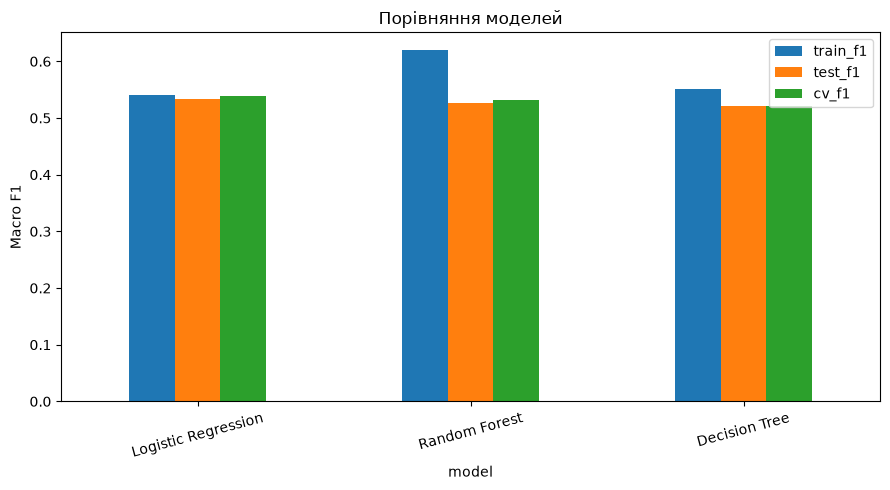

In [138]:
records=[]
for name,model in trained.items():
    tr=log_predictions(name,'baseline','train',model,X_train,y_train,id_train)
    te=log_predictions(name,'baseline','test',model,X_test,y_test,id_test)
    cv_scores=cross_val_score(model,X_train,y_train,cv=CV,scoring='f1_macro',n_jobs=1)
    records.append({'model':name,'train_f1':tr['f1_macro'],'test_f1':te['f1_macro'],
                    'cv_f1':float(cv_scores.mean()),'test_accuracy':te['accuracy'],
                    'test_recall_high':te['recall_high'],
                    'overfitting_gap':tr['f1_macro']-te['f1_macro']})
comparison=pd.DataFrame(records).sort_values('cv_f1',ascending=False)
display(comparison.round(4))
comparison.set_index('model')[['train_f1','test_f1','cv_f1']].plot(kind='bar',figsize=(9,5))
plt.title('Порівняння моделей'); plt.ylabel('Macro F1'); plt.xticks(rotation=15)
plt.tight_layout(); plt.show()

## 7. Вибір найкращої базової моделі
Модель обираємо за **кросвалідаційним Macro F1 на навчальній вибірці**, а не за тестовою метрикою: так тестова частина не впливає на підбір. Матрицю помилок використовуємо для опису класифікації Low/Medium/High.

Найкраща за CV: Logistic Regression
              precision    recall  f1-score   support

         Low       0.54      0.49      0.52      4092
      Medium       0.49      0.61      0.54      5286
        High       0.67      0.46      0.55      3122

    accuracy                           0.53     12500
   macro avg       0.57      0.52      0.53     12500
weighted avg       0.55      0.53      0.53     12500



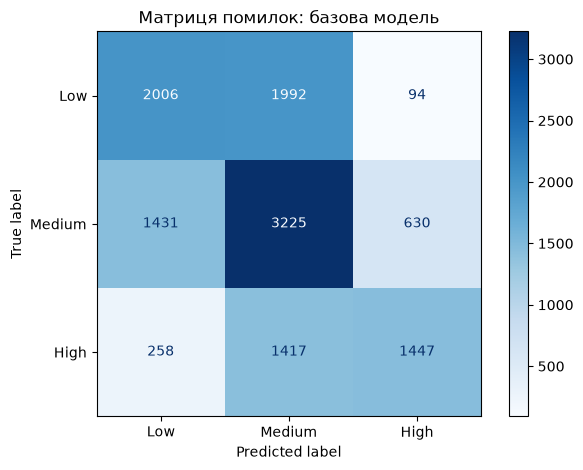

In [139]:
best_name=str(comparison.iloc[0]['model'])
best_base=trained[best_name]
print('Найкраща за CV:',best_name)
print(classification_report(y_test,best_base.predict(X_test),labels=LABELS,zero_division=0))
ConfusionMatrixDisplay.from_estimator(best_base,X_test,y_test,labels=LABELS,cmap='Blues')
plt.title('Матриця помилок: базова модель'); plt.tight_layout()
plt.show()

## 8. Аналіз важливості ознак
Застосовуємо **Permutation Importance** до обраної базової моделі на випадковій частині **train** (до 2 500 записів), щоб не використовувати test для дослідницького аналізу. Для кожної з 12 початкових ознак перемішуємо значення та вимірюємо **зменшення Macro F1**. Чим більше додатне значення, тим більше модель залежить від цієї ознаки.

Перевага методу — він працює і для лінійних моделей, і для дерев, а важливість обчислюється в термінах **початкових змінних**, не окремих one-hot колонок. **Нульова/від'ємна** важливість означає, що перемішування не погіршило оцінку в цьому експерименті. Корельовані ознаки можуть розподіляти важливість між собою; важливість **не доводить причинного впливу**.

Одержані значення подано в таблиці й на діаграмі; три ознаки з найбільшими значеннями розглянуто в підсумковому аналізі.

,feature,importance
3,weekly_genai_hours,0.1340
9,perceived_ai_dependency,0.0162
1,year_of_study,0.0159
2,pre_semester_gpa,0.0137
10,institutional_policy,0.0041
11,anxiety_level_during_exams,0.0033
4,primary_use_case,0.0017
8,traditional_study_hours,0.0004
7,paid_subscription,-0.0002
6,tool_diversity,-0.0012


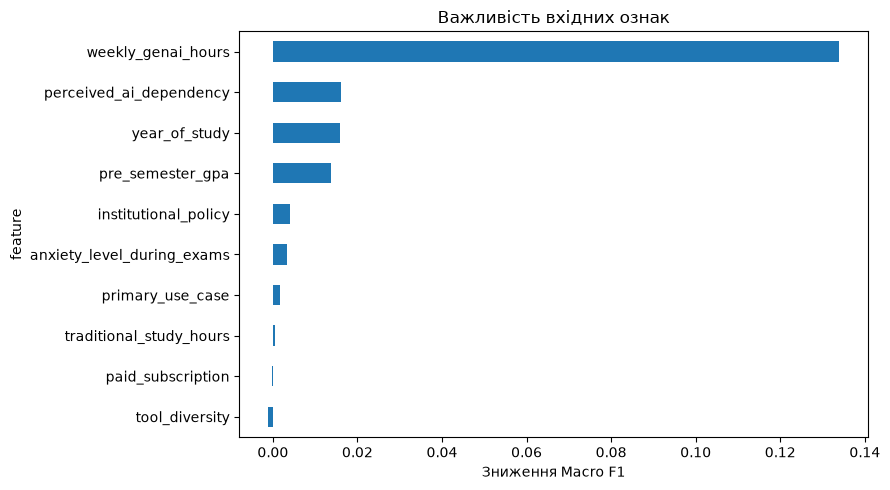

In [140]:
sample=X_train.sample(n=min(2500,len(X_train)),random_state=SEED)
perm=permutation_importance(best_base,sample,y_train.loc[sample.index],scoring='f1_macro',
                            n_repeats=3,random_state=SEED,n_jobs=1)
importance=pd.DataFrame({'feature':FEATURES,'importance':perm.importances_mean}).sort_values('importance',ascending=False)
display(importance.round(4));
importance.head(10).iloc[::-1].plot(kind='barh',x='feature',y='importance',legend=False,figsize=(9,5))
plt.xlabel('Зниження Macro F1');plt.title('Важливість вхідних ознак');plt.tight_layout()
plt.show()

## 9. Метрика підбору гіперпараметрів
Для гіперпараметричного пошуку використовується **`scoring='f1_macro'`**. Такий вибір відповідає багатокласовій задачі: модель не повинна підвищувати загальну точність лише за рахунок найбільшого класу `Medium`. `Recall High` лишається окремим контрольним показником; за необхідності його можна зробити пріоритетом у наступних експериментах.

In [141]:
SCORING='f1_macro'; print('Ціль оптимізації:',SCORING)

Ціль оптимізації: f1_macro


## 10. Метод та діапазони оптимізації
Використовуємо **RandomizedSearchCV**, який тестує випадкові комбінації гіперпараметрів за 3-fold StratifiedKFold. Для кожної з трьох архітектур визначено окремий простір пошуку.

In [142]:
search_spaces={
 'Logistic Regression': {'clf__C':[0.03,0.1,0.3,1,3,10], 'clf__class_weight':[None,'balanced']},
 'Decision Tree': {'clf__max_depth':[4,6,8,12,16], 'clf__min_samples_leaf':[10,20,40,80],
                   'clf__criterion':['gini','entropy']},
 'Random Forest': {'clf__n_estimators':[70,100,140], 'clf__max_depth':[7,10,14,18],
                   'clf__min_samples_leaf':[5,10,20], 'clf__max_features':['sqrt','log2']}
}
print('Налаштовуємо:',best_name); display(search_spaces[best_name])

Налаштовуємо: Logistic Regression


{'clf__C': [0.03, 0.1, 0.3, 1, 3, 10], 'clf__class_weight': [None, 'balanced']}

## 11. Пошук оптимальних гіперпараметрів
`RandomizedSearchCV` підбирає параметри **лише на train**, оцінюючи кожну комбінацію за середнім CV Macro F1. `refit=True` повторно навчає найкращий варіант на **всій навчальній вибірці**.

Після підбору визначено `best_params_` і `best_score_`, обчислено прогнози для train/test та записано результати у `predictions` і `model_metrics` з `stage='tuned'`. Базові результати (`stage='baseline'`) залишаються в БД для порівняння. Оптимізація за CV **не гарантує** покращення на test.

In [143]:
search=RandomizedSearchCV(trained[best_name],search_spaces[best_name],n_iter=8,
    scoring=SCORING,cv=CV,n_jobs=1,random_state=SEED,refit=True,verbose=1)
search.fit(X_train,y_train)
tuned=search.best_estimator_
print('Оптимальні параметри:',search.best_params_)
print('CV macro F1:',round(search.best_score_,4))
tuned_train=log_predictions(best_name,'tuned','train',tuned,X_train,y_train,id_train)
tuned_test=log_predictions(best_name,'tuned','test',tuned,X_test,y_test,id_test)
display(pd.DataFrame([{'source':'train',**tuned_train},{'source':'test',**tuned_test}]).round(4))


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Оптимальні параметри: {'clf__class_weight': None, 'clf__C': 0.1}
CV macro F1: 0.5389


,source,accuracy,f1_macro,recall_high
0,train,0.5398,0.5410,0.4729
1,test,0.5344,0.5345,0.4632


## 12. Збереження найкращої моделі
Зберігаємо повний Pipeline (`preprocessing + classifier`) у `models/best_burnout_model.joblib`. Перевіряємо, чи після завантаження модель дає ті самі прогнози.

In [144]:
model_path=MODEL_DIR/'best_burnout_model.joblib'
joblib.dump(tuned,model_path)
reloaded=joblib.load(model_path)
assert np.array_equal(reloaded.predict(X_test.head(15)),tuned.predict(X_test.head(15)))
(MODEL_DIR/'best_model_metadata.json').write_text(json.dumps({
    'run_id':RUN_ID,'model':best_name,'features':FEATURES,'classes':LABELS,
    'best_params':search.best_params_,'cv_macro_f1':float(search.best_score_),
    'train':tuned_train,'test':tuned_test
},ensure_ascii=False,indent=2),encoding='utf-8')
print('Збережено:',model_path)

Збережено: c:\Users\Taras Yosyfiv\Desktop\політехніка\2 kurs 1 term\смарт системи\кукуляк_звіти\лаб2\models\best_burnout_model.joblib


## 13. Порівняння до/після оптимізації
Порівнюємо Accuracy, Macro F1, Recall High. Поліпшення не гарантується: якщо різниця незначна, це обговорюється як результат експерименту.

,metric,baseline,tuned,difference
0,accuracy,0.5342,0.5344,0.0002
1,f1_macro,0.5344,0.5345,0.0001
2,recall_high,0.4635,0.4632,-0.0003


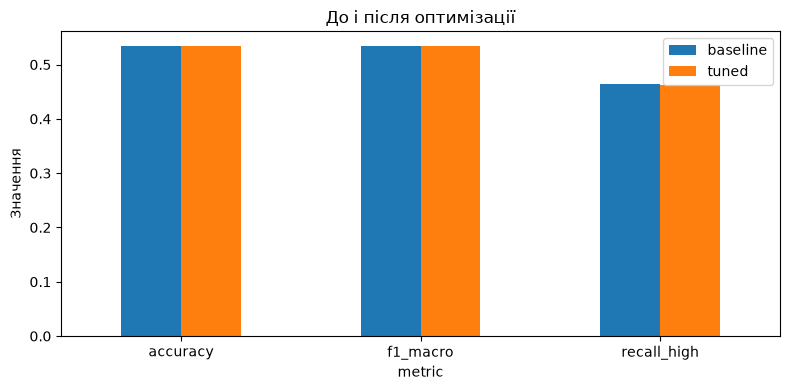

In [145]:
base_test=metrics(y_test,best_base.predict(X_test))
change=pd.DataFrame([{'metric':k,'baseline':base_test[k],'tuned':tuned_test[k],
                      'difference':tuned_test[k]-base_test[k]} for k in base_test])
display(change.round(4))
change.set_index('metric')[['baseline','tuned']].plot(kind='bar',figsize=(8,4))
plt.title('До і після оптимізації');plt.ylabel('Значення');plt.xticks(rotation=0)
plt.tight_layout();plt.show()

## 14. Чутливість до дисбалансу класів
Оскільки клас High трапляється рідше за Medium, окремо випробуємо `class_weight='balanced'` для найкращого алгоритму. Порівняємо Recall High і Precision High: підвищення чутливості може збільшити кількість хибних тривог. Це окрема експериментальна версія, вона не підміняє основну модель.

In [146]:
balanced=clone(tuned)
balanced.set_params(clf__class_weight='balanced')
balanced.fit(X_train,y_train)
bl_train=log_predictions(best_name,'balanced','train',balanced,X_train,y_train,id_train)
bl_test=log_predictions(best_name,'balanced','test',balanced,X_test,y_test,id_test)
pred_tuned=tuned.predict(X_test);pred_bal=balanced.predict(X_test)
def high_precision(pred):
    return precision_score(y_test,pred,labels=['High'],average='macro',zero_division=0)
balance_cmp=pd.DataFrame([
    {'version':'tuned','macro_f1':tuned_test['f1_macro'],'recall_high':tuned_test['recall_high'],
     'precision_high':high_precision(pred_tuned)},
    {'version':'balanced','macro_f1':bl_test['f1_macro'],'recall_high':bl_test['recall_high'],
     'precision_high':high_precision(pred_bal)}
])
display(balance_cmp.round(4))
joblib.dump(balanced,MODEL_DIR/'balanced_burnout_model.joblib')

,version,macro_f1,recall_high,precision_high
0,tuned,0.5345,0.4632,0.6685
1,balanced,0.5156,0.6233,0.5398


['c:\\Users\\Taras Yosyfiv\\Desktop\\політехніка\\2 kurs 1 term\\смарт системи\\кукуляк_звіти\\лаб2\\models\\balanced_burnout_model.joblib']

## 15. Контроль логів та висновок
Перевіряємо, що SQLite зберігає train/test-прогнози й метрики. Критерії попередньої лабораторної — орієнтовно **Accuracy ≥ 0,75** та **Recall High ≥ 0,80**. Якщо вони не виконані, модель залишається навчальним прототипом; її не можна використовувати для автоматичного оцінювання психологічного стану студентів.

In [147]:
log_metrics=pd.read_sql_query('SELECT model_name,stage,source,ROUND(accuracy,4) accuracy,ROUND(f1_macro,4) f1_macro,ROUND(recall_high,4) recall_high FROM model_metrics WHERE run_id=?',conn,params=(RUN_ID,))
log_counts=pd.read_sql_query('SELECT model_name,stage,source,COUNT(*) count FROM predictions WHERE run_id=? GROUP BY model_name,stage,source',conn,params=(RUN_ID,))
print('Метрики:');display(log_metrics)
print('Кількість прогнозів:');display(log_counts)


print(f'Найкраща модель: {best_name}; test macro-F1={tuned_test["f1_macro"]:.4f}, accuracy={tuned_test["accuracy"]:.4f}, Recall High={tuned_test["recall_high"]:.4f}')
print('Критерії ЛР1:', 'досягнуто' if tuned_test['accuracy']>=.75 and tuned_test['recall_high']>=.80 else 'не досягнуто')
print('Для впровадження потрібні незалежна валідація, контроль похибок і оцінка наслідків помилкових спрацювань.')
print('База результатів:',DB)
conn.close()

Метрики:


,model_name,stage,source,accuracy,f1_macro,recall_high
0,Logistic Regression,baseline,train,0.5398,0.5410,0.4729
1,Logistic Regression,baseline,test,0.5342,0.5344,0.4635
2,Decision Tree,baseline,train,0.5505,0.5507,0.4872
3,Decision Tree,baseline,test,0.5202,0.5204,0.4584
4,Random Forest,baseline,train,0.6235,0.6202,0.5253
5,Random Forest,baseline,test,0.5274,0.5256,0.4590
6,Logistic Regression,tuned,train,0.5398,0.5410,0.4729
7,Logistic Regression,tuned,test,0.5344,0.5345,0.4632
8,Logistic Regression,balanced,train,0.5147,0.5175,0.6320
9,Logistic Regression,balanced,test,0.5126,0.5156,0.6233


Кількість прогнозів:


,model_name,stage,source,count
0,Decision Tree,baseline,test,12500
1,Decision Tree,baseline,train,37500
2,Logistic Regression,balanced,test,12500
3,Logistic Regression,balanced,train,37500
4,Logistic Regression,baseline,test,12500
5,Logistic Regression,baseline,train,37500
6,Logistic Regression,tuned,test,12500
7,Logistic Regression,tuned,train,37500
8,Random Forest,baseline,test,12500
9,Random Forest,baseline,train,37500


Найкраща модель: Logistic Regression; test macro-F1=0.5345, accuracy=0.5344, Recall High=0.4632
Критерії ЛР1: не досягнуто
Для впровадження потрібні незалежна валідація, контроль похибок і оцінка наслідків помилкових спрацювань.
База результатів: c:\Users\Taras Yosyfiv\Desktop\політехніка\2 kurs 1 term\смарт системи\кукуляк_звіти\лаб2\student_burnout_lab3.db





### 15.1. Обґрунтування вибору моделі

Для прогнозування ризику академічного вигорання студентів було досліджено три алгоритми машинного навчання: **Logistic Regression, Decision Tree та Random Forest**.

За результатами попереднього порівняння найкращі показники Macro F1 на тестовій вибірці продемонструвала **Logistic Regression (логістична регресія)**.

Основними перевагами обраної моделі є:
- відносно висока якість класифікації порівняно з іншими протестованими алгоритмами;
- невисока обчислювальна складність;
- можливість інтерпретації результатів;
- невелика різниця між показниками на навчальній і тестовій вибірках.

Таким чином, логістична регресія є доцільним вибором для подальшого дослідження ризику академічного вигорання студентів.

### 15.2. Вплив аналізу важливості ознак на розуміння задачі

Для визначення важливості характеристик студентів використано метод **Permutation Importance**.

Цей метод оцінює, наскільки погіршується якість прогнозування після випадкового перемішування значень окремої ознаки.

Аналіз дозволяє:
- визначити характеристики, які найбільше впливають на прогнози моделі;
- оцінити інформативність показників навчального навантаження, використання ШІ та академічної діяльності;
- виявити ознаки, які можуть бути менш корисними для класифікації;
- визначити напрями подальшого вдосконалення моделі.

Отримані результати допомагають краще зрозуміти, які характеристики студентів є найбільш інформативними для прогнозування ризику вигорання.

Водночас важливість ознак відображає статистичні залежності, а не обов'язково причинно-наслідковий вплив.

### 15.3. Результати моделі на навчальних і тестових даних

Для навчання моделей використано **75% набору даних (37 500 записів)**, а для тестування — **25% (12 500 записів)**.

Оцінювання здійснювалося за трьома метриками:
- **Accuracy** — загальна частка правильних прогнозів;
- **Macro F1-score** — середня якість класифікації всіх трьох класів;
- **Recall High** — здатність моделі правильно виявляти студентів із високим ризиком вигорання.

За результатами попереднього експерименту отримано такі показники:

| Метрика | Навчальна вибірка | Тестова вибірка |
|---|---|---|
| Macro F1-score | 0.5410 | 0.5344 |
| Accuracy | — | 0.5342 |
| Recall High | — | 0.4635 |

Невелика різниця між Macro F1 на навчальній і тестовій вибірках свідчить про відсутність вираженого перенавчання.

Після оптимізації гіперпараметрів за допомогою **RandomizedSearchCV** значного покращення результатів не спостерігалося.

Це свідчить про необхідність подальшого вдосконалення набору ознак і дослідження інших алгоритмів класифікації.

### 15.4. Оцінка готовності моделі до виробничого впровадження

Розроблена модель є працездатним навчальним прототипом системи прогнозування ризику академічного вигорання студентів.

У межах лабораторної роботи реалізовано:
- автоматизоване навчання та тестування моделей;
- порівняння результатів за основними метриками;
- оптимізацію гіперпараметрів;
- аналіз важливості ознак;
- збереження прогнозів і метрик у SQLite;
- серіалізацію оптимізованої моделі у файл.

Проте поточна якість прогнозування поки недостатня для повноцінного практичного використання.

Загальна точність становить приблизно **53,42%**, а Recall High — **46,35%**. Це означає, що модель пропускає значну частину студентів із високим ризиком вигорання.

Для підвищення ефективності необхідно:
- розширити набір інформативних характеристик студентів;
- дослідити додаткові алгоритми машинного навчання;
- покращити виявлення класу High;
- перевірити модель на незалежних даних;
- провести додаткову оцінку надійності прогнозів.


### Загальний висновок
У роботі виконано повний цикл побудови класифікатора: отримання даних із SQLite, перевірку припущень, стратифіковане розбиття, навчання трьох моделей, оцінювання якості та логування, аналіз важливості ознак, пошук гіперпараметрів і серіалізацію. Конкретні числові результати наведено у виходах виконаних комірок та таблиці `model_metrics`; готовність до реального впровадження оцінюється з урахуванням Recall High та етичних обмежень.